Public-contract revision 2026-10-29

Version2.0-nonnegative-population-smooth-dust-class resolves provisional isolation using unchanged full198SSP forward/2308point standard errors and original chi-square boundary1.0374388649929949. Added original feasible log-dust TV and Calzetti color-summary log-RMS budgets, independently calibrated at float64 and float32 precision; the latter avoids punishing the already allowed float32 quantization. Grey attenuation is explicitly an unidentifiable positive common scale because template medians remove it. Independent public-data simplex-NNLS variable projection with5smooth log-curve perturbations (a control subfamily, not a replacement output/model restriction) reaches chi-square.98388445346036, TV.2291475554940, colorlogRMS.01003767758158; no hidden population/curve or source imports used. Permuted populations give chi-square28.94017; wrong E gives colorlogRMS1.13049; positive grey factor7 leaves all current metrics invariant as required. No actual population/dust truth exists, and this is not claimed to reproduce FIREFLY finite BIC selection. Source/arrays unchanged. Earlier private-array agreement numbers are historical v1 parity diagnostics; current acceptance uses the public physical/regularity class.

# Problem

Recover a galaxy's **stellar population light distribution** and relative dust/continuum attenuation from actual SDSS spectroscopy. The galaxy is plate0266/MJD51602/fiber0001, with catalog redshift0.02127545. A single observed spectrum combines many stellar ages and metallicities; dust can mimic old or metal-rich continua. The unknown is a198-component mixture, a2308-point smooth attenuation function, and its Calzetti color-excess summary.

This notebook actively executes the complete two-stage FIREFLY reconstruction in local mathematical code. The original implementation was independently run on the same supported observations. Its outputs are comparison references, **not measured population truth**. Full original measurements remain visible, including a disclosed template-boundary failure in an earlier binding. The comparison logic follows the published spectrum/attenuation/population/degeneracy analysis; broad survey and alternative stellar-library experiments are outside this single-acquisition binding.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data,normalize_models
from src.solvers import reconstruct,fit_population
from src.physics_model import forward,calzetti
from src.visualization import acquisition_figure,population_figure,dust_figure,exploration_figure,residual_statistic
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
data=load_data()
with np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z:original={k:z[k] for k in z.files}
with np.load('notebooks/reference_outputs/rejected_edge.npz',allow_pickle=False) as z:rejected={k:z[k] for k in z.files}
def show(figure,name):
    if os.environ.get('IMAGING_REVIEW_DIR'):
        destination=Path(os.environ['IMAGING_REVIEW_DIR']);destination.mkdir(parents=True,exist_ok=True);figure.savefig(destination/('firefly_'+name+'.png'),dpi=140)
    plt.show()
print('Measured detector bins:',len(data['observed_flux']),'context bins:',len(data['context_flux']),'supported bins:',len(data['flux']),'independent templates:',len(data['templates']))

Measured detector bins: 3835 context bins: 2327 supported bins: 2308 independent templates: 198


# Data

The author-distributed FITS spectrum contains3835 original detector bins, wavelength and inverse variance. We retain all of them in the public NPZ. After the author's emission masking and template matching,2327 measured rest-frame bins provide context. The independent MILES template boundary is7429 Angstrom; broadening with zero padding corrupts its extreme red edge. The first attempted binding had five all-zero template bins and an unmasked residual mean-square8.82. That result was rejected and archived.

The declared3750–7400 Angstrom support lies inside this known boundary; the original bin matching drops its last incomplete bin, giving2308 actual points. The mask is fixed by calibration support, not by residual quality. Every supported point enters the final observation check, even when the original fitting objective clips some residuals. Catalog velocity dispersion135.8996km/s, resolving power2000, foreground map E(B-V)=0.0938292mag and independent M11/MILES/Kroupa templates are available calibration. No galaxy population estimate is a public calibration.

Flux is in1e-17 erg s^-1 cm^-2 Angstrom^-1. Template units are luminosity density per solar mass; median normalization removes their absolute scale, so this task does not infer absolute stellar mass. Population age is inGyr and metallicity is relative to solar.

# Physics

Let $y_i,s_i$ denote measured flux and standard error, $T_{ji}$ a matched population template and $a_i>0$ the relative attenuation. The light fraction $w_j$ of each population is nonnegative and sums to one. For $N=2308$ observations and $M=198$ templates,

$$B_{ji}(a)=\frac{T_{ji}a_i}{\mathrm{median}_{k}(T_{jk}a_k)}\mathrm{median}_{k}(y_k),\qquad \mu_i=\sum_{j=1}^{M}w_jB_{ji}(a).$$

Here $\mu$ is predicted flux. Absorption-line shape informs age/metallicity, whereas broad continuum differences contain dust and calibration effects. Similar templates make the mixture nonunique. For fixed attenuation the model is linear in weights, with adjoint $B r$ for a wavelength residual vector $r$; its inner-product identity is independently tested.

The reported observation statistic uses all supported data:

$$Q=\frac1N\sum_{i=1}^{N}\left(\frac{\mu_i-y_i}{s_i}\right)^2.$$

This is a mean standardized squared residual, **not** a degrees-of-freedom-corrected reduced chi-square. No clipping, translation, flux rescaling or reference-based masking is allowed in this evaluation.

# Method

The local implementation retains the original two complete fitting stages. First, a discrete Fourier window suppresses broad continuum modes while retaining DC normalization. If $h$ is its high-pass inverse transform and $l$ the complementary continuum transform with DC restored, the actual original operator is

$$H(f)=\left[1+\frac{h-\mathrm{median}(h)}{l}\right]\mathrm{median}(h).$$

The code uses its original20-bin ramps starting at mode20 and its exact reverse indexing; it does not replace this with an ideal filter. Fit the filtered data with filtered, median-normalized SSPs. With resulting mixture $v$, let $b=vB$ and $b_H=vB_H$ be unfiltered and filtered predicted spectra. Derive

$$f_i=\frac{y_i}{b_i}-\frac{H(y)_i}{(b_H)_i}+1,\qquad a_i=\mathrm{median}_{|\lambda_k-\lambda_i|<200\,\mathrm{Angstrom}}\frac{f_k}{\mathrm{median}(f)}.$$

The nonfinite-ratio guard sets such fine values to1; it is inactive on this final supported binding. Fit the closest median-normalized Calzetti law on200 E(B-V) values from0 to1.5mag, but apply the **empirical smooth curve** to templates for the second complete population fit. The original extinction objective sigma-clips squared curve differences and then sums their squares, so it is a fourth-power discrepancy, explicitly labeled below.

Each population fit initializes every single SSP, clips its standardized residual at three standard deviations and chooses the best initial mask. At branching iteration $t$, test every retained parent and every added SSP:

$$w'=\frac{t w+e_j}{\sum_k t w_k+1},\qquad c(w')<\min_{\mathrm{retained}}c-\log N.$$

Here $e_j$ is a unit template vector and $c$ the selected clipped squared-residual objective. Stop when no child passes. Next mix each best-ten candidate with **every** retained candidate over eight dilution factors from1e-7 through1. Preserve all such mixtures and choose the minimum. The current original implementation uses the minimum threshold; this differs from the paper's median-description passage. The negative information-penalty sign follows the BIC definition, despite the inconsistent sign printed in its Eq2. Stage objectives and masks are method-specific; near-optimal candidates are shown as degeneracy diagnostics, not asserted posterior probabilities.

In [2]:
start=time.perf_counter();out,result=reconstruct(data);elapsed=time.perf_counter()-start
Path('output').mkdir(exist_ok=True);np.savez_compressed('output/reconstruction.npz',**out)
np.savez_compressed('notebooks/reference_outputs/cleaned.npz',**out,prediction=result['prediction'],highpass_weights=result['highpass']['fit']['best_weights'])
report,exit_code=judge.evaluate('output/reconstruction.npz');assert exit_code==0,report
print('Fresh complete two-stage runtime [s]:',elapsed)
print('Highpass / final candidate counts:',len(result['highpass']['fit']['chis']),len(result['final']['chis']))
print('Fresh measured metrics:',json.dumps(report['metrics'],indent=2))
print('Recovered E(B-V) [mag]:',out['ebv'][0,0])

Fresh complete two-stage runtime [s]: 2.776128299999982
Highpass / final candidate counts: 17577 19602
Fresh measured metrics: {
  "mean_standardized_squared_residual": 0.9880370142790428,
  "log_attenuation_tv": 0.28357812438393876,
  "color_law_logrms": 0.045619682841926606
}
Recovered E(B-V) [mag]: 0.03768844221105527


# Results

The first comparison keeps every original detector bin visible, overlays the fresh supported-band spectrum and independently reproduced native result, and plots every supported residual. The final panel exposes the earlier zero-padding failure and its predeclared support limit. A small clipped fitting objective alone would have hidden this failure; the observation-consistency metric does not.

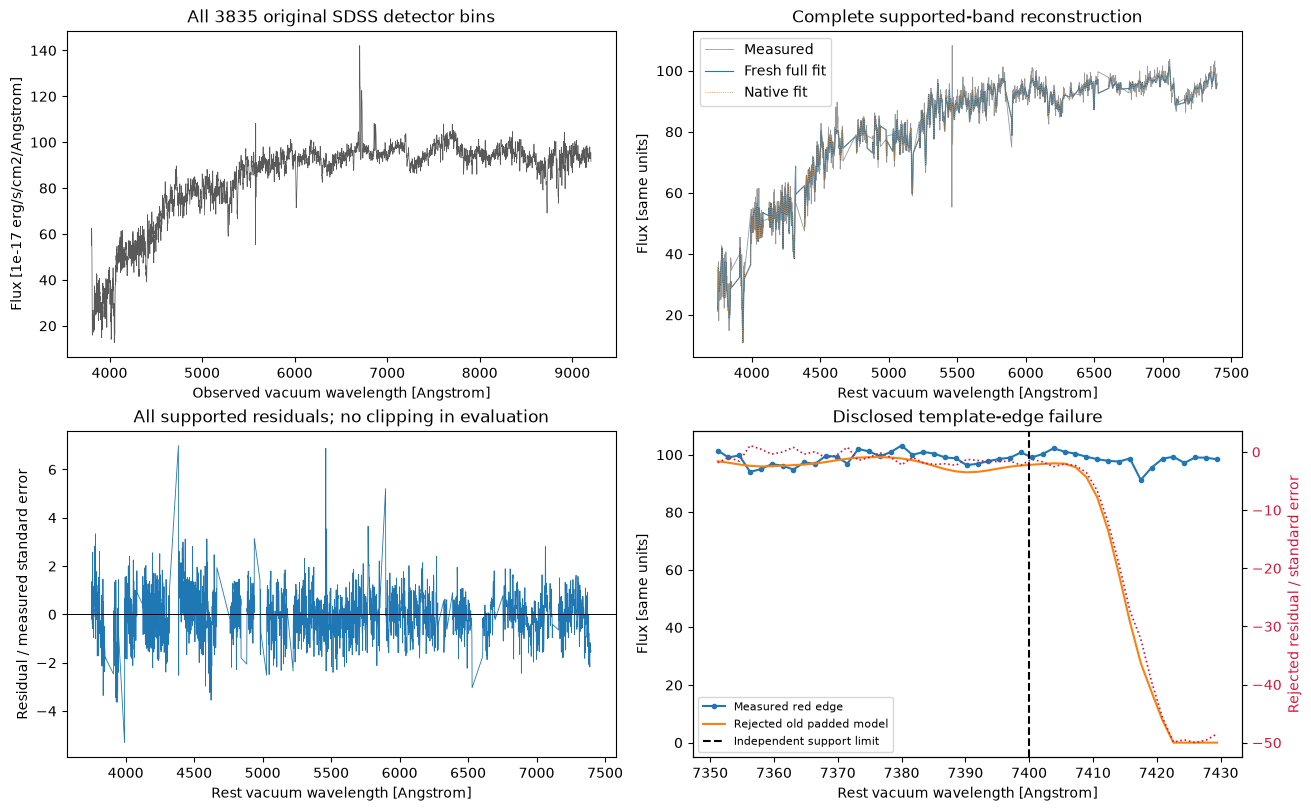

In [3]:
show(acquisition_figure(data,result,original,rejected),'acquisition')

The recovered population is displayed on all198 supplied age/metallicity nodes, with summed age and metallicity marginals. The native/fresh coefficient comparison covers the whole vector. These are normalized light fractions under one stellar library and continuum convention, not a unique star-formation history or independent mass measurement.

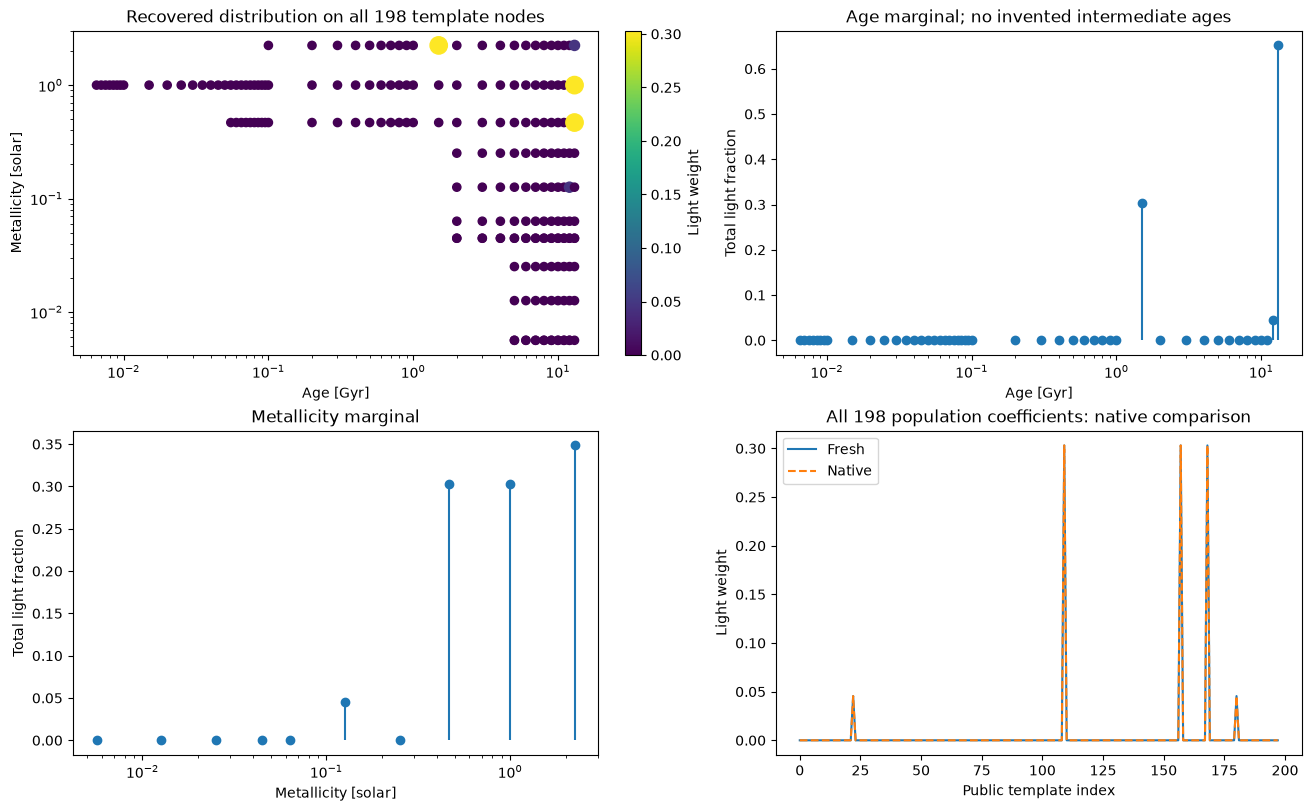

In [4]:
show(population_figure(data,out,original),'population')

The next experiment computes two additional full population fits on the same supported measurements: no intrinsic continuum attenuation, and the closest analytic Calzetti curve. They are freshly solved comparisons, not archived substitutions. The first panel preserves the paper's fine-versus-smooth attenuation and analytic-law comparison; the age marginal reveals how continuum assumptions change physical interpretation.

Both fresh full comparison fits [s]: 3.5619397999253124
Empirical attenuation Q= 0.9880370142790428
No attenuation Q= 1.7806951953612689
Calzetti-only Q= 1.3132433472219804


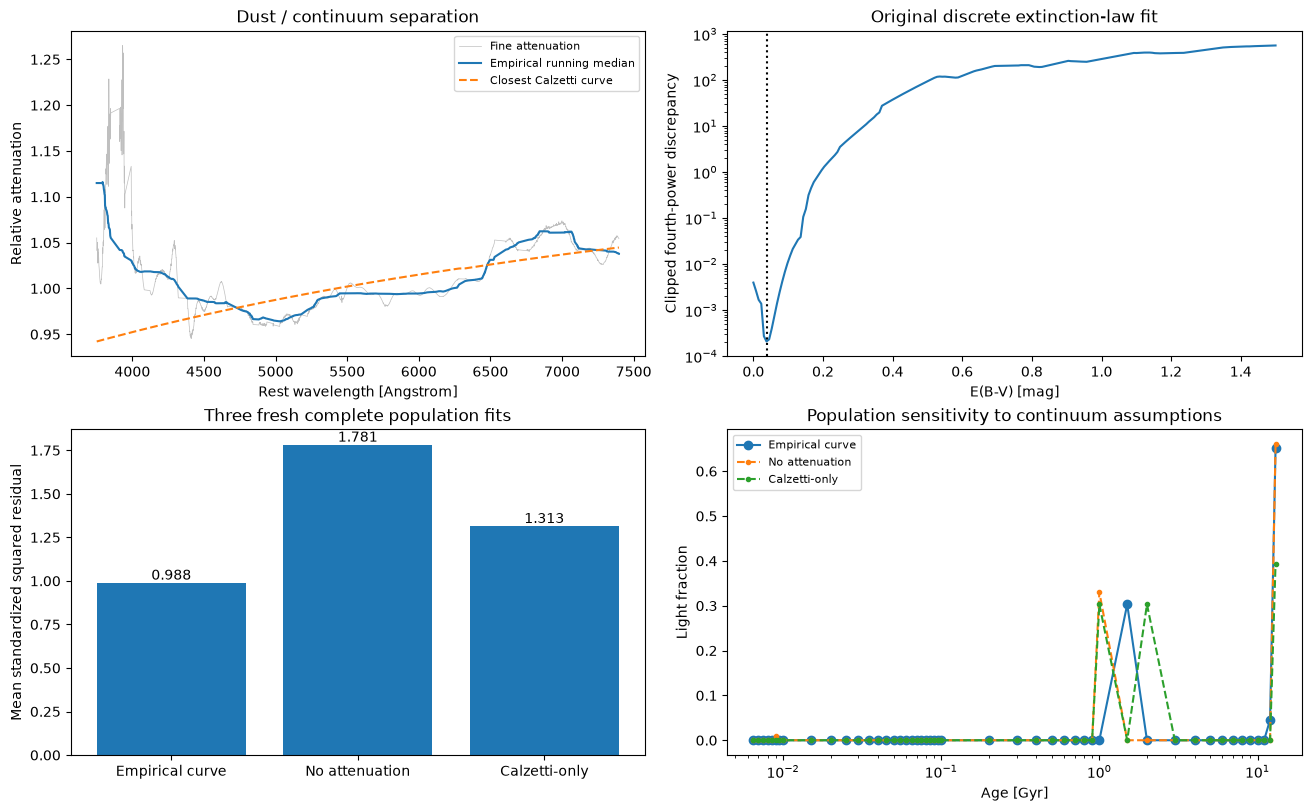

In [5]:
start=time.perf_counter()
no_dust=fit_population(data['flux'],data['uncertainty'],normalize_models(data['flux'],data['templates']))
no_dust['prediction']=forward(no_dust['best_weights'],np.ones(len(data['flux'])),data['templates'],data['flux'])
analytic=calzetti(out['ebv'][0,0],data['wavelength']);analytic/=np.median(analytic)
calzetti_fit=fit_population(data['flux'],data['uncertainty'],normalize_models(data['flux'],data['templates']*analytic))
calzetti_fit['prediction']=forward(calzetti_fit['best_weights'],analytic,data['templates'],data['flux'])
print('Both fresh full comparison fits [s]:',time.perf_counter()-start)
for name,prediction in [('Empirical attenuation',result['prediction']),('No attenuation',no_dust['prediction']),('Calzetti-only',calzetti_fit['prediction'])]:print(name,'Q=',residual_statistic(prediction,data))
show(dust_figure(data,out,result,no_dust,calzetti_fit),'dust')

The retained candidate cloud visualizes light-weighted mean log age and log metallicity for objective differences below10. The histogram includes the complete final exploration, while both histories show actual BIC progression and stopping before mixing. These diagnostics preserve the published motivation to explore spectral degeneracies; they do not turn a discrete, clipping-dependent search into calibrated confidence intervals.

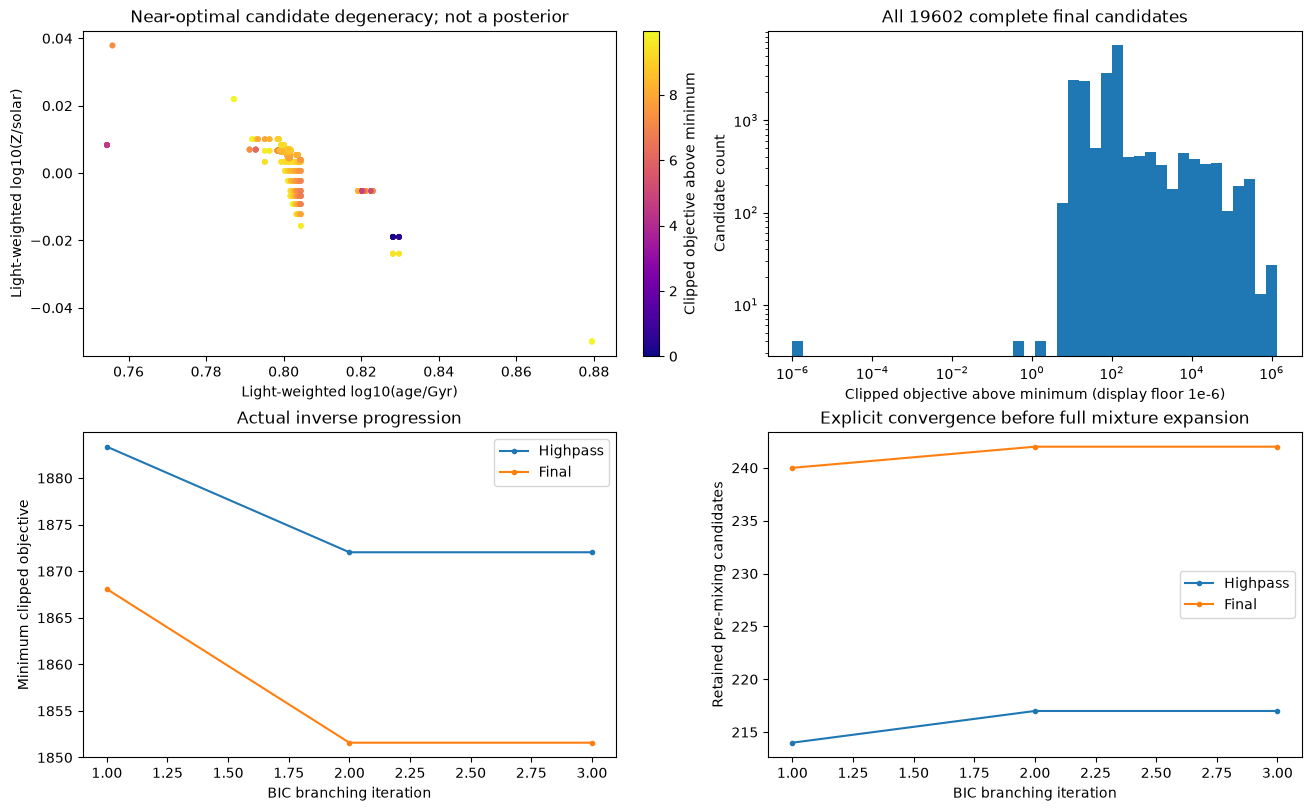

In [6]:
show(exploration_figure(data,result),'exploration')

# Conclusion

The fresh complete local reconstruction agrees with the independently run original method and fits every supported observation with mean standardized squared residual near0.99. Both dust estimation and population search were actively executed, including all candidate mixtures; extra continuum comparisons were also computed here. The rejected padding-contaminated result is retained as visible evidence, not absorbed into a permissive accuracy threshold.

The remaining astrophysical limitations are age–metallicity–dust degeneracy, empirical library assumptions, fixed catalog broadening, incomplete emission subtraction and missing preprocessing covariance. Relative attenuation can absorb smooth calibration structure; its Calzetti summary need not reproduce its detailed shape. No independent stellar-population truth exists. We therefore report method reproducibility and observation consistency separately from physical accuracy.

Primary method: Wilkinson et al2017, DOI10.1093/mnras/stx2215, arXiv1711.00865v1. Independent model library: Maraston and Strömbäck2011, DOI10.1111/j.1365-2966.2011.19738.x. Exact source revisions, instrument provenance, original runs, all fixture consumers and numeric criteria are recorded in `test/validation.md`.